# Phase 1 · Monthly Sentinel-2 composites

Cloud-masked median composites (B02, B03, B04, B08, B11, B12) from Planetary Computer for three AOIs, shown as true-colour RGB and NDVI.

* Reflectance = (DN − 1000) / 10000 for processing baseline ≥ 04.00, clipped to [0, 1].
* SCL classes 0, 1, 3, 8, 9, 10 are masked before the per-pixel median.
* Composites are cached as COGs under `cache/<aoi>/<YYYY-MM>/composite.tif`, so re-running is instant.

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np

from pipeline import config as cfg
from pipeline.fetch import monthly_composite, ndvi

SAMPLES = [("hasdeo", "2025-01"), ("rondonia", "2025-07"), ("mato_grosso", "2025-07")]

In [2]:
composites = {}
for aoi_id, month in SAMPLES:
    aoi = cfg.get_aoi(aoi_id)
    t0 = time.perf_counter()
    comp = monthly_composite(aoi, month)
    composites[aoi_id] = (month, comp)
    status = "ok" if comp.clear_fraction >= cfg.MIN_CLEAR_FRACTION else "skip (cloudy)"
    print(
        f"{aoi.name:40s} {month}  {comp.data.shape[1]}x{comp.data.shape[2]} px  "
        f"scenes={comp.n_items}  clear={comp.clear_fraction:6.1%}  {status}  "
        f"({time.perf_counter() - t0:.1f}s)"
    )

Hasdeo Arand, Chhattisgarh (India)       2025-01  2918x3115 px  scenes=6  clear=100.0%  ok  (0.7s)


Jaci-Paraná, Rondônia (Brazil)           2025-07  3997x4407 px  scenes=6  clear=100.0%  ok  (1.4s)


Northern Mato Grosso (Brazil)            2025-07  3338x3289 px  scenes=6  clear=100.0%  ok  (0.8s)


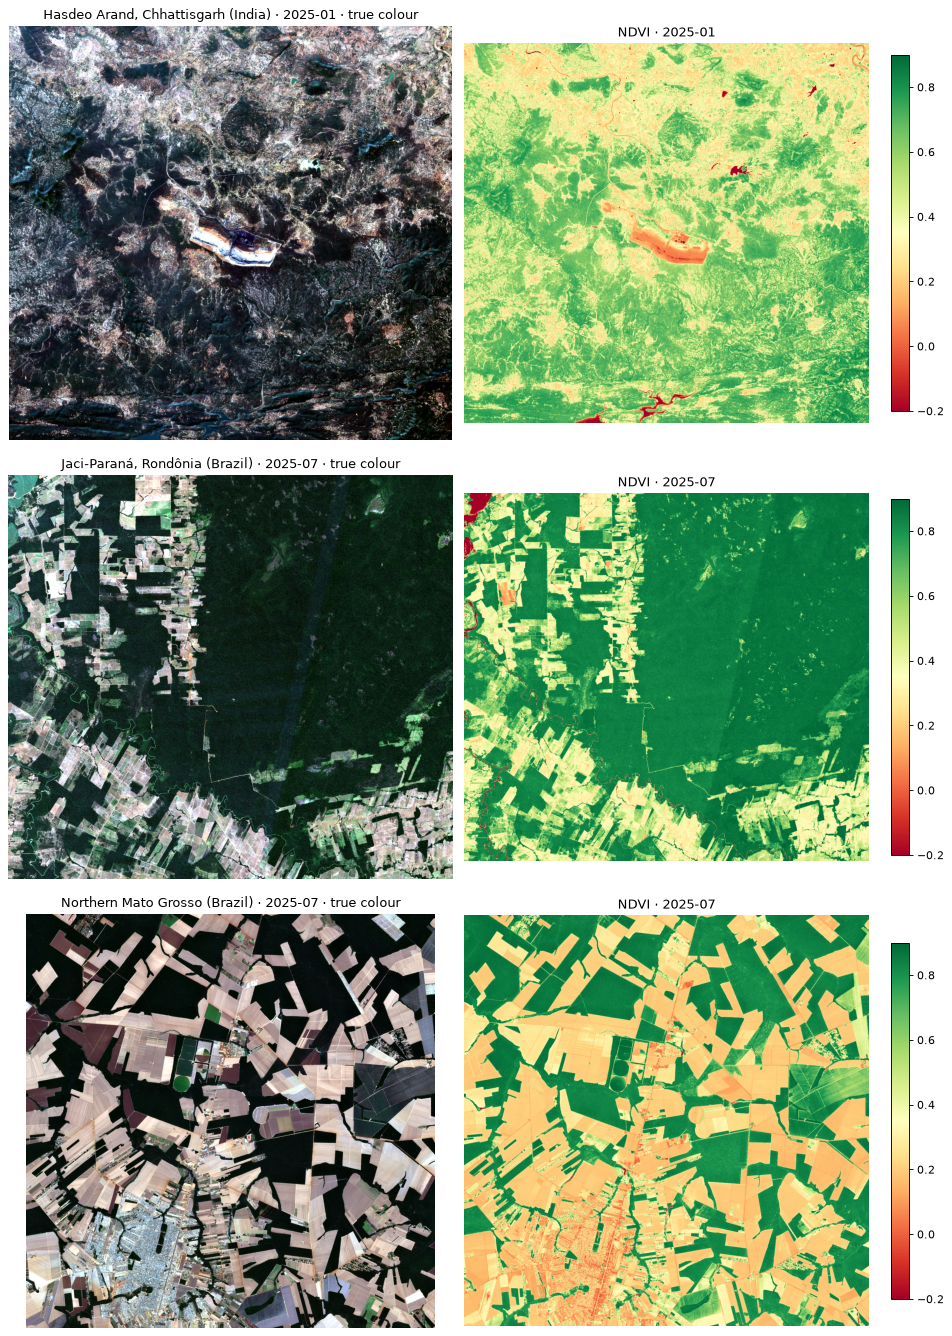

In [3]:
def stretch(rgb: np.ndarray, lo: float = 2, hi: float = 98) -> np.ndarray:
    """Per-channel percentile stretch to [0, 1] for display."""
    p_lo, p_hi = np.nanpercentile(rgb, [lo, hi], axis=(0, 1))
    return np.clip((rgb - p_lo) / (p_hi - p_lo), 0, 1)


fig, axes = plt.subplots(len(SAMPLES), 2, figsize=(12, 5.6 * len(SAMPLES)), dpi=80)
for row, (aoi_id, (month, comp)) in zip(axes, composites.items(), strict=True):
    step = max(1, max(comp.data.shape[1:]) // 1200)  # thin out pixels for display only
    d = comp.data[:, ::step, ::step]
    rgb = stretch(np.moveaxis(d.sel(band=["B04", "B03", "B02"]).values, 0, -1))
    nd = ndvi(d.sel(band="B04"), d.sel(band="B08")).values
    row[0].imshow(np.nan_to_num(rgb))
    row[0].set_title(f"{cfg.get_aoi(aoi_id).name} · {month} · true colour")
    im = row[1].imshow(nd, cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    row[1].set_title(f"NDVI · {month}")
    fig.colorbar(im, ax=row[1], fraction=0.04)
    for ax in row:
        ax.set_axis_off()
fig.tight_layout()
(ROOT / "docs").mkdir(exist_ok=True)
fig.savefig(ROOT / "docs" / "phase1_composites.png", dpi=80, bbox_inches="tight")

In [4]:
print(f"{'AOI':14s} {'NDVI p2':>8s} {'p50':>6s} {'p98':>6s} {'NDVI>0.6':>9s}")
for aoi_id, (_, comp) in composites.items():
    nd = ndvi(comp.data.sel(band="B04"), comp.data.sel(band="B08")).values
    p2, p50, p98 = np.nanpercentile(nd, [2, 50, 98])
    print(f"{aoi_id:14s} {p2:8.2f} {p50:6.2f} {p98:6.2f} {np.nanmean(nd > 0.6):9.1%}")

AOI             NDVI p2    p50    p98  NDVI>0.6
hasdeo             0.17   0.55   0.77     42.5%


rondonia           0.26   0.83   0.90     74.3%
mato_grosso        0.09   0.28   0.88     39.2%


**Reading the panels.** Dense canopy shows NDVI ≈ 0.6–0.9 (dark green); open-cast mine pits (Hasdeo), pasture and fresh clearings (Rondônia, Mato Grosso) sit near 0–0.3. Dry-season months are used because they give the most cloud-free scenes; note Hasdeo's sal forest is partly leaf-off in winter, which is why change detection later requires both the model and an NDVI drop to agree.